# Chapter 10: Proving a Bandit Worked: Holdouts and Honest Numbers

This notebook runs every piece of code in the chapter, in order, with the chapter's text around it. Read the chapter on the site: [Proving a Bandit Worked: Holdouts and Honest Numbers](https://books.sugiv.fyi/lift/proving-lift.html). Everything is simulated from seeded code in `sim/`, so a run gives the same numbers as the book.

In [1]:
# Run this cell first. In Google Colab it fetches the companion repo; anywhere else, run the
# notebook from a clone of it. Either way it moves to the repo's root so `sim` can be imported.
import os
import pathlib
import sys

if "google.colab" in sys.modules:
    if not pathlib.Path("/content/lift-not-luck").exists():
        !git clone -q --depth 1 https://github.com/sugix/lift-not-luck /content/lift-not-luck
    %pip install -q pingouin
candidates = [pathlib.Path.cwd(), *pathlib.Path.cwd().parents, pathlib.Path("/content/lift-not-luck")]
root = next(p for p in candidates if (p / "sim" / "parlo.py").is_file())
os.chdir(root)
sys.path.insert(0, str(root))

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import pingouin as pg
def glue(name, value, display=True):
    """In the book, glue() puts a computed number into the text. Here the numbers are already
    written into the text, so it only shows the value when asked to."""
    if display:
        from IPython.display import display as show
        show(value)

from sim import parlo, proof as P, style

style.apply()
pd.set_option("display.precision", 4)


def glue_num(name, value):
    glue(name, float(value), display=False)


H = P.run_with_holdout(runs=300, seed=1)
bandit_rate = H.bandit_lessons.sum(1) / H.bandit_sends.sum(1)
holdout_rate = H.holdout_lessons.sum(1) / H.holdout_sends.sum(1)
glue_num("ba_lift", 100 * (bandit_rate - H.before_rate).mean())
glue_num("ho_lift", 100 * (bandit_rate - holdout_rate).mean())

Here's the finding first. Parlo launched its reminder bandit and compared the month after launch with the week before. The lesson rate went up by **1.0 points**. A small random group that kept the old reminder tells a different story: the bandit actually added **2.2 points**, roughly twice as much. Learners were studying less as the summer went on, and the before/after comparison blamed the bandit for the slump.

That's the theme of this chapter. **A bandit can't grade its own homework.** Its dashboard answers the wrong question, with numbers that are subtly biased. Two cheap habits fix both problems: a random holdout, and logged propensities.

## Two questions, two tools

After a bandit has run for a while, people ask two different questions:

1. **"Which message is best, and by how much?"** That's about the arms. The tool is propensity weighting.
2. **"How much better off are we with the bandit than without it?"** That's about the whole system. The tool is a holdout.

The bandit's own dashboard, the average lesson rate of each message, seems to answer the first question and is often quoted as an answer to the second. It does neither well.

## The dashboard's numbers are biased

Here's a thought experiment. A message gets unlucky in its first few hundred sends, so the bandit sends it less. Its estimate never gets the chance to recover, because the bandit stopped collecting the data that would correct it. A message that got *lucky* keeps being sent, and the extra data pulls its estimate back to the truth. The result is an asymmetry: **messages the bandit abandons are systematically underestimated.**

Here's how big that is for Chapter 7's four reminders: 20 days, 500 reminders a day, averaged over 300 simulated launches. "Floor" is the share of sends spread at random, the exploration Chapter 9 told us never to drop to zero.

In [3]:
rows = []
for floor in [0.0, 0.05]:
    log = P.run_logged(runs=300, floor=floor, seed=1)
    m, lo, hi, n = P.naive_means(log)
    for k, name in enumerate(P.NAMES):
        rows.append({"floor": f"{floor:.0%}", "message": name, "true rate": P.RATES[k],
                     "dashboard average": m[:, k].mean(),
                     "bias (relative)": m[:, k].mean() / P.RATES[k] - 1,
                     "95% CI covers truth": ((lo[:, k] <= P.RATES[k]) & (P.RATES[k] <= hi[:, k])).mean(),
                     "sends": n[:, k].mean()})
    if floor == 0.05:
        floored_log = log
bias = pd.DataFrame(rows).set_index(["floor", "message"])
bias.style.format({"true rate": "{:.3f}", "dashboard average": "{:.4f}",
                   "bias (relative)": "{:+.1%}", "95% CI covers truth": "{:.0%}", "sends": "{:,.0f}"})

In [4]:
no_floor = bias.loc["0%"]
losers = no_floor.drop("Juno says hi")
glue_num("bias_lo", -100 * losers["bias (relative)"].max())
glue_num("bias_hi", -100 * losers["bias (relative)"].min())
glue_num("cover_min", 100 * no_floor["95% CI covers truth"].min())

With no exploration floor, the three messages the bandit gave up on are underestimated by 6% to 8%, and the "95%" intervals cover the truth as little as 88% of the time. The winner, "Juno says hi", is estimated almost perfectly, because it gets most of the data. A 5% floor shrinks the problem but doesn't remove it.

In practice this matters more than it looks. "Progress recap converts at 9.3%" ends up in a slide. Someone decides the recap is a dud and deletes it. It was actually at 10%, nearly as good as the runner-up.

### The fix: weight by the propensity

Chapter 9 introduced inverse propensity scoring (IPS) for evaluating a *new* policy; it's the same idea as inverse propensity weighting (IPW). The same trick fixes the per-message numbers. Every send counts towards every message's estimate: a send of message $k$ counts $1/p_k$ times, where $p_k$ is the probability the bandit had of sending $k$ at that moment. Sends of rarely chosen messages count a lot, which exactly cancels out how rarely they were chosen.

In [5]:
m, lo, hi, _ = P.naive_means(floored_log)
im, ilo, ihi = P.ipw_means(floored_log)
R = P.RATES
pd.DataFrame({
    "true rate": R,
    "dashboard bias": m.mean(0) / R - 1,
    "IPW bias": im.mean(0) / R - 1,
    "dashboard CI covers": ((lo <= R) & (R <= hi)).mean(0),
    "IPW CI covers": ((ilo <= R) & (R <= ihi)).mean(0),
    "IPW spread / dashboard spread": im.std(0) / m.std(0),
}, index=P.NAMES).style.format({"true rate": "{:.3f}", "dashboard bias": "{:+.1%}",
                                "IPW bias": "{:+.1%}", "dashboard CI covers": "{:.0%}",
                                "IPW CI covers": "{:.0%}", "IPW spread / dashboard spread": "{:.1f}x"})

,true rate,dashboard bias,IPW bias,dashboard CI covers,IPW CI covers,IPW spread / dashboard spread
Plain nudge,0.090,-4.6%,+1.8%,93%,94%,1.4x
Streak at risk,0.105,-4.2%,+0.5%,95%,95%,1.3x
Juno says hi,0.120,-0.4%,+0.3%,95%,98%,1.0x
Progress recap,0.100,-4.5%,-0.0%,94%,95%,1.4x


IPW removes the bias, and its intervals cover the truth about as often as they claim to. The price is noise: the estimates for rarely sent messages are wider. That's the honest picture of how little the bandit learned about them. It's also why the exploration floor matters: IPW divides by $p_k$, and if $p_k$ gets close to zero, a single send can swing the estimate wildly.

<details>
<summary><b>Under the hood: why IPW is unbiased under adaptive sampling</b></summary>

At send $t$ the bandit picks arm $A_t$ with probability $p_t(k)$, which depends on everything seen before $t$. Define $Z_t(k) = \mathbf 1\{A_t = k\}\, Y_t / p_t(k)$. Conditional on the past, $\mathbb E[Z_t(k)] = p_t(k) \cdot \mu_k / p_t(k) = \mu_k$, whatever $p_t$ is. So $\frac1T\sum_t Z_t(k)$ averages terms that are each unbiased for $\mu_k$, which is what makes it unbiased even though the sampling adapted. The sample mean has no such property, because its denominator, the number of sends of $k$, depends on the outcomes. For valid confidence intervals under adaptivity, Hadad and colleagues (Hadad et al., 2021) reweight these terms so that a martingale central limit theorem applies.

</details>

## What did the bandit add? Use a holdout

The per-message numbers, even corrected, don't answer the business question. To know what the bandit added, you need to compare it with what would have happened without it. You need a **holdout**: a random slice of learners, here 10%, who keep getting the old reminder ("Plain nudge") after launch.

Parlo's launch had a complication that every real launch has in some form. Over the 37 days, everyone's study rate drifted down by about a quarter, because summer arrived. Nobody planned it, and it has nothing to do with the bandit.

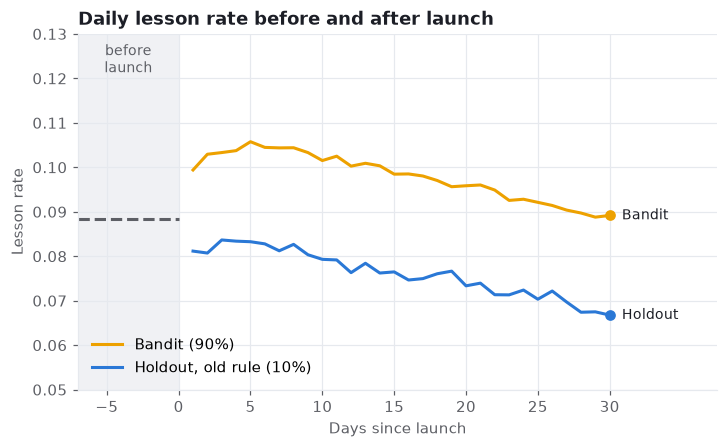

In [6]:
days = H.bandit_sends.shape[1]
b_daily = (H.bandit_lessons / H.bandit_sends).mean(0)
h_daily = (H.holdout_lessons / H.holdout_sends).mean(0)

fig, ax = plt.subplots()
x = np.arange(1, days + 1)
ax.axvspan(-7, 0, color=style.GRID, alpha=0.6, linewidth=0)
ax.text(-3.5, 0.128, "before\nlaunch", ha="center", va="top", fontsize=9, color=style.MUTED)
ax.hlines(H.before_rate.mean(), -7, 0, color=style.MUTED, linewidth=2, linestyles="--")
ax.plot(x, b_daily, color=style.SERIES[3], label="Bandit (90%)")
ax.plot(x, h_daily, color=style.SERIES[0], label="Holdout, old rule (10%)")
style.label_line_end(ax, x[-1], b_daily[-1], "Bandit", style.SERIES[3])
style.label_line_end(ax, x[-1], h_daily[-1], "Holdout", style.SERIES[0])
ax.set(title="Daily lesson rate before and after launch", xlabel="Days since launch",
       ylabel="Lesson rate")
ax.set_xlim(-7, days * 1.25)
ax.set_xticks(range(-5, days + 1, 5))
ax.set_ylim(0.05, 0.13)
ax.legend(loc="lower left")
plt.show()

The before/after comparison sets the bandit's month against the week before launch, so it subtracts the summer slump from the bandit's effect. The holdout lives through the same summer as the bandit, so the slump cancels out, and the gap between the two lines is the bandit's real contribution.

Here's the readout for one launch, using Pingouin's chi-squared test on the post-launch totals:

In [7]:
run = 0
counts = pd.DataFrame({
    "group": ["bandit", "holdout"],
    "sends": [H.bandit_sends[run].sum(), H.holdout_sends[run].sum()],
    "lessons": [H.bandit_lessons[run].sum(), H.holdout_lessons[run].sum()],
}).set_index("group")
counts["rate"] = counts.lessons / counts.sends

long = pd.DataFrame({
    "group": np.repeat(["bandit", "holdout"], counts.sends.astype(int)),
    "lesson": np.concatenate([
        np.r_[np.ones(int(counts.lessons[g])), np.zeros(int(counts.sends[g] - counts.lessons[g]))]
        for g in ["bandit", "holdout"]]),
})
_, _, stats = pg.chi2_independence(long, x="group", y="lesson")

diff = counts.rate["bandit"] - counts.rate["holdout"]
se = np.sqrt((counts.rate * (1 - counts.rate) / counts.sends).sum())
print(counts.round(4))
print(f"\nlift: {100 * diff:.2f} points, 95% CI {100 * (diff - 1.96 * se):.2f} to "
      f"{100 * (diff + 1.96 * se):.2f}, p = {stats.query('test == \"pearson\"').pval.iloc[0]:.2g}")

           sends  lessons    rate
group                            
bandit   26959.0   2611.0  0.0969
holdout   3041.0    241.0  0.0793

lift: 1.76 points, 95% CI 0.74 to 2.78, p = 0.0019


That's a number you can defend to a CFO. It's a randomised comparison, it lives through the same summer, and it has an honest interval.

## How big should the holdout be?

Every learner in the holdout gets the worse reminder, so the holdout has a cost. A smaller holdout costs less but measures less precisely. Pingouin's `power_ttest2n` handles unequal group sizes, so it can trace the trade-off directly. With 30,000 reminders a month, a holdout rate of 7.6% and a true lift of 2.2 points:

In [8]:
N, base, lift = 30_000, 0.076, 0.022
d = lift / np.sqrt(base * (1 - base))   # effect size in standard deviations
rows = []
for share in [0.01, 0.02, 0.05, 0.10, 0.20]:
    rows.append({"holdout share": share,
                 "power to detect the lift": pg.power_ttest2n(nx=int(N * (1 - share)),
                                                              ny=int(N * share), d=d),
                 "lessons given up per month": N * share * lift})
pd.DataFrame(rows).set_index("holdout share").style.format(
    {"power to detect the lift": "{:.0%}", "lessons given up per month": "{:.0f}"}).format_index("{:.0%}")

,power to detect the lift,lessons given up per month
holdout share,,
1%,30%,7
2%,52%,13
5%,88%,33
10%,99%,66
20%,100%,132


Going from 1% to 5% buys a lot of certainty for very little cost. Going beyond 10% buys almost nothing. My default is a **5 to 10% holdout, kept for the life of the system**, not just for launch. That way you can show the bandit's value every quarter, and you'll notice if it ever stops adding any. Kohavi, Tang and Xu (Kohavi et al., 2020) describe the same practice, under the name *global holdout*, for whole experimentation programmes.

> **Warning**
>
> The holdout must be **random at the learner level** and **sticky**: the same learner stays in the holdout for the whole period. "Everyone in Canada" or "learners who signed up on Tuesdays" aren't holdouts. Those groups differ in other ways, and you're back to a before/after comparison in disguise.

## An honest re-read of Better Mortgage

The JustAI case study (JustAI, 2026) reports that, in one journey, application starts rose from 9.25% to 12.08% on about 2,600 homebuyers per arm, "roughly 30%". That's a holdout-style comparison, which is exactly right. Let's read it with the tools from this chapter.

In [9]:
n = 2600
starts = {"control": round(0.0925 * n), "treatment": round(0.1208 * n)}
df = pd.DataFrame({
    "group": np.repeat(list(starts), n),
    "start": np.concatenate([np.r_[np.ones(s), np.zeros(n - s)] for s in starts.values()]),
})
_, _, stats = pg.chi2_independence(df, x="group", y="start")

p0, p1 = starts["control"] / n, starts["treatment"] / n
se = np.sqrt(p0 * (1 - p0) / n + p1 * (1 - p1) / n)
lo, hi = p1 - p0 - 1.96 * se, p1 - p0 + 1.96 * se
print(f"lift {100 * (p1 - p0):.2f} points, 95% CI {100 * lo:.2f} to {100 * hi:.2f}")
print(f"relative lift {100 * (p1 / p0 - 1):.0f}%, CI roughly {100 * lo / p0:.0f}% to {100 * hi / p0:.0f}%")
print(f"p = {stats.query('test == \"pearson\"').pval.iloc[0]:.3f}")

lift 2.85 points, 95% CI 1.17 to 4.52
relative lift 31%, CI roughly 13% to 49%
p = 0.001


The lift is real: the chance of a gap this large from noise alone is about one in a thousand. But "30%" is the middle of a range that runs from about 13% to about 49%. Both ends would be good news for the business. The honest headline is "a solid lift, most likely between 13% and 49%". That sets better expectations than a single number, and it tells you a bigger holdout would be needed to pin it down.

## Juno: proving a router saves money

For Juno's LLM router from Chapter 9, the holdout is a random slice of learners whose lessons always go to the large model, the old default. Two parts of the comparison behave very differently:

- **Cost** is known exactly for every lesson. No holdout is needed to measure it; the bill tells you.
- **Quality** (lessons completed) is noisy and needs the holdout.

That split matters, because small quality differences need large samples. Here's the sample size, per group, to detect a given drop in completion rate with 80% power:

In [10]:
rows = []
for drop in [0.01, 0.02, 0.05]:
    d = drop / np.sqrt(0.8 * 0.2)
    rows.append({"completion drop to detect": drop,
                 "lessons per group (80% power)": pg.power_ttest(d=d, power=0.8)})
pd.DataFrame(rows).set_index("completion drop to detect").style.format(
    {"lessons per group (80% power)": "{:,.0f}"}).format_index("{:.0%}")

,lessons per group (80% power)
completion drop to detect,
1%,"25,117"
2%,"6,280"
5%,"1,006"


A router usually *saves* money by accepting a tiny quality drop on easy tasks. Detecting a 1-point quality drop with 80% power needs about 25,000 lessons in each group, and proving the drop is *under* a 1-point margin needs at least as many. So report the savings, which are exact, and the quality change with its interval, which is honest. Then let the business decide whether the interval is tight enough. This chapter's lesson applies to agents with full force: the router's own estimates of model quality are just as biased as Parlo's message dashboard, for exactly the same reason.

> **In the wild**
>
> The Better Mortgage result (JustAI, 2026) is credible for the reason this chapter gives: it was measured against a group that didn't get the optimised journey, not by comparing before and after. Many published bandit "wins" are dashboard numbers from the bandit itself. When you read one, look first for the holdout.

## Pitfalls

- **Before/after.** Anything else that changes over time (seasons, marketing, a new app version) gets credited to the bandit. Use a concurrent holdout.
- **Trusting the dashboard.** Per-arm averages under adaptive sampling are biased against the arms the bandit dropped. Use IPW with logged propensities.
- **Holdouts that aren't random.** Geography, sign-up date or platform aren't random assignment.
- **Leaky holdouts.** Holdout learners who see bandit-chosen messages through another channel (email, in-app) dilute the comparison. Hold out the learner, not the send.
- **Ending the holdout at launch.** A bandit's value can decay as content wears out (Chapter 8). Keep a small permanent holdout and check it every quarter.

## Exercises

1. **No slump.** Rerun the launch with `slump=0`. How close do before/after and the holdout get? What does that tell you about when before/after is safe?
2. **Holdout of one percent.** Run 300 launches with `holdout=0.01`. In what fraction is the lift statistically significant? Compare with the power table.
3. **Winner's curse.** Make two messages tie for best at 12%. Is the dashboard's estimate of the *chosen* winner now biased upwards? Why?

## Further reading

Hadad, Hirshberg, Zhan, Wager and Athey (Hadad et al., 2021) show how to build valid confidence intervals from adaptively collected data. Kohavi, Tang and Xu (Kohavi et al., 2020) is the practitioner's reference on holdouts, guardrails and trustworthy experimentation, and Part I of this book leans on it heavily.